In [1]:
# 1. Imports + Configuration

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter
from matplotlib.patches import Polygon

plt.rcParams["mathtext.fontset"] = "cm"
plt.rcParams["font.family"] = "serif"

# Settings
FPS = 60
MAX_LEVEL = 5

TRANSITION_SECONDS = 4.0
HOLD_SECONDS = 3.0
INITIAL_HOLD_SECONDS = 1

OUTPUT_FILE = "mandeltree.mp4"

FIGSIZE = (12.8, 7.2)
DPI = 300

# Visual Settings
BACKGROUND_COLOR = "black"
FILL_COLOR = "white"
TEXT_COLOR = "white"
SHOW_LABELS = True

USE_CURVED_ARCS = True

BASE_Y = -0.35

ARC_SAMPLES = {
    0: 120,
    1: 60,
    2: 28,
    3: 12,
    4: 6,
    5: 4,
    6: 3,
}

LEVEL_NOTES = {
    0: "single parent arc",
    1: "seven-piece precursor",
    2: "thirteen-piece generator",
    3: "first full recursive subdivision",
    4: "second full recursive subdivision",
    5: "third full recursive subdivision",
    6: "fourth full recursive subdivision",
}

if MAX_LEVEL not in ARC_SAMPLES:
    raise ValueError(
        f"No arc sample setting defined for Level {max_level}."
    )

# Every finished boundary piece is a 60 degree arc.
BASE_SWEEP = -np.pi / 3

In [2]:
# 2. Core Geometry

def seven_segment_generator(parity):
    
    if parity not in (-1, +1):
        raise ValueError("parity must be +1 or -1.")

    position = 0j
    heading = 0.0
    children = []

    regular_step = 1 / 3
    exceptional_step = 1 / (np.sqrt(3))

    def turn(degrees):
        nonlocal heading
        heading += parity * np.deg2rad(degrees)

    def step(length, parity_factor):
        nonlocal position

        next_position = position + length * np.exp(1j * heading)

        children.append((
            position,
            next_position,
            parity * parity_factor,
        ))

        position = next_position

    # Construct the initial 7 segments in order.
    turn(60)
    step(regular_step, -1)

    turn(0)
    step(regular_step, +1)

    turn(-60)
    step(regular_step, +1)

    turn(-60)
    step(regular_step, +1)

    turn(-90)
    step(exceptional_step, -1)

    turn(150)
    step(regular_step, -1)

    turn(0)
    step(regular_step, +1)

    return children


# Precompute the original and reflected generators.
SEVEN_GENERATORS = {
    parity: seven_segment_generator(parity)
    for parity in (+1, -1)
}

def thirteen_segment_generator(parity):
    base_generator = SEVEN_GENERATORS[parity]
    start, end, child_parity = base_generator[4]

    # ??? Preserve complex displacement for scaling and rotation
    parent_vector = end - start
    
    replacement_generator = SEVEN_GENERATORS[child_parity]

    replacement_segments = []

    # Transform all seven replacement segments
    for child_start, child_end, replacement_parity in replacement_generator:
        transformed_start = start + parent_vector * child_start
        transformed_end = start + parent_vector * child_end

        replacement_segments.append((
            transformed_start,
            transformed_end,
            replacement_parity
        ))

    thirteen_segments = base_generator[0:4] + replacement_segments + base_generator[5:]
    
    return thirteen_segments

# Precompute both 13-segment orientations
GENERATORS = {parity: thirteen_segment_generator(parity)
              for parity in (+1, -1)
             }

def subdivide_stage(stage):
    children = []

    for start, end, parity in stage:
        parent_vector = end - start

        for child_start, child_end, child_parity in GENERATORS[parity]:
            children.append((
                start + parent_vector * child_start,
                start + parent_vector * child_end,
                child_parity,
            ))

    return children

In [3]:
# 2.a Geometry Validation

TOL = 1e-12

# Validate the seven-segment generator
seven_positive = SEVEN_GENERATORS[+1]

expected_vertices = [
    0j,
    1/6 + 1j * np.sqrt(3)/6,
    1/3 + 1j * np.sqrt(3)/3,
    2/3 + 1j * np.sqrt(3)/3,
    5/6 + 1j * np.sqrt(3)/6,
    1/3 + 0j,
    2/3 + 0j,
    1 + 0j,
]

actual_vertices = [
    start for start, end, parity in seven_positive
] + [seven_positive[-1][1]]

assert np.allclose(
    actual_vertices, expected_vertices,
    rtol=0, atol=TOL
)

expected_seven_parities = [-1, +1, +1, +1, -1, -1, +1]

for parity, segments in SEVEN_GENERATORS.items():
    assert len(segments) == 7

    parities = [p for _, _, p in segments]
    assert parities == [parity * p for p in expected_seven_parities]

    lengths = [abs(end - start) for start, end, _ in segments]

    assert np.count_nonzero(
        np.isclose(lengths, 1/3, rtol=0, atol=TOL)
    ) == 6

    assert np.count_nonzero(
        np.isclose(lengths, 1/np.sqrt(3), rtol=0, atol=TOL)
    ) == 1

    for k in range(len(segments) - 1):
        assert np.isclose(
            segments[k][1], segments[k + 1][0],
            rtol=0, atol=TOL
        )



# Validate the 13-segment generators
positive_generator = GENERATORS[+1]
negative_generator = GENERATORS[-1]

expected_parities = [
    -1, +1, +1, +1, +1, -1, -1,
    -1, +1, +1, -1, -1, +1
]

for parity, segments in GENERATORS.items():
    assert len(segments) == 13

    assert np.isclose(segments[0][0], 0j, rtol=0, atol=TOL)
    assert np.isclose(segments[-1][1], 1 + 0j, rtol=0, atol=TOL)

    parities = [p for _, _, p in segments]
    assert parities == [parity * p for p in expected_parities]

    lengths = [abs(end - start) for start, end, _ in segments]

    assert np.count_nonzero(
        np.isclose(lengths, 1/3, rtol=0, atol=TOL)
    ) == 7

    assert np.count_nonzero(
        np.isclose(lengths, 1/(3*np.sqrt(3)), rtol=0, atol=TOL)
    ) == 6

    for k in range(len(segments) - 1):
        assert np.isclose(
            segments[k][1], segments[k + 1][0],
            rtol=0, atol=TOL
        )

# Validate geometric reflection
reflection_errors = []

for positive, negative in zip(positive_generator, negative_generator):
    for coordinate_index in (0, 1):
        reflection_errors.append(
            abs(
                negative[coordinate_index]
                - positive[coordinate_index].conjugate()
            )
        )

assert max(reflection_errors) <= TOL

# 4. Validate recursive subdivision
stage_0 = [(0j, 1 + 0j, +1)]
stage_1 = subdivide_stage(stage_0)
stage_2 = subdivide_stage(stage_1)

assert len(stage_0) == 1
assert len(stage_1) == 13
assert len(stage_2) == 169

for stage in (stage_1, stage_2):
    assert np.isclose(stage[0][0], 0j, rtol=0, atol=TOL)
    assert np.isclose(stage[-1][1], 1 + 0j, rtol=0, atol=TOL)

    for k in range(len(stage) - 1):
        assert np.isclose(
            stage[k][1], stage[k + 1][0],
            rtol=0, atol=TOL
        )

# Report validation results
print("All geometry validation checks passed.")
print(f"Maximum reflection error: {max(reflection_errors):.3e}")


All geometry validation checks passed.
Maximum reflection error: 0.000e+00


In [4]:
# 3. Arc Rendering

def render_many_arcs(starts, ends, sweeps, points_per_arc):

    # Sample multiple circular arcs and return flattened complex coordinates
    starts = np.asarray(starts, dtype=complex).ravel()
    ends = np.asarray(ends, dtype=complex).ravel()
    sweeps = np.asarray(sweeps, dtype=float).ravel()

    # Optional straight-line rendering
    if not USE_CURVED_ARCS:
        sweeps = np.zeros_like(sweeps)

    if not len(starts) == len(ends) == len(sweeps):
        raise ValueError("starts, ends, and sweeps must have equal lengths.")

    number_of_arcs = len(starts)
    u = np.linspace(0.0, 1.0, points_per_arc)
    points = np.empty((number_of_arcs, points_per_arc), dtype=complex)

    if points_per_arc < 2:
        raise ValueError("points_per_arc must be at least 2.")
    
    chord = ends - starts
    chord_length = np.abs(chord)
    degenerate = chord_length < 1e-12
    nearly_straight = np.abs(sweeps) < 1e-6

    # Zero length pieces
    if np.any(degenerate):
        points[degenerate] = starts[degenerate, None]
        
    # Handle 0 curvature lines in animation
    straight = nearly_straight & ~degenerate
    
    if np.any(straight):
        points[straight] = starts[straight, None] + chord[straight, None] * u
        
    # True circular arcs
    curved = ~nearly_straight & ~degenerate

    if np.any(curved):
        curved_starts = starts[curved]
        curved_ends = ends[curved]
        curved_sweeps = sweeps[curved]
        curved_chords = chord[curved]
        curved_lengths = chord_length[curved]
        unit = curved_chords / curved_lengths

        # Multiplication by i rotates a complex
        # vector 90 degrees counterclockwise.

        left_normal = (1j * unit)
        midpoint = (curved_starts + curved_ends) / 2
        center_offset = curved_lengths / (2 * np.tan(curved_sweeps / 2))
        centers = midpoint + center_offset * left_normal
        radii = curved_lengths / (2 * np.abs(np.sin(curved_sweeps / 2)))

        start_angles = np.angle(curved_starts - centers)
        theta = start_angles[:, None] + curved_sweeps[:, None] * u
        points[curved] = centers[:, None] + radii[:, None] * np.exp(1j * theta)

    return points.reshape(-1)

def render_stage(stage, points_per_arc):
    
    # Convert a completed recursive stage into sampled circular arcs.
    starts = np.array([start for (start, _, _) in stage], dtype=complex)
    ends = np.array([end for (_, end, _) in stage], dtype=complex)
    parities = np.array([parity for (_, _, parity) in stage], dtype=float)

    sweeps = BASE_SWEEP * parities
    
    return render_many_arcs(
        starts,
        ends,
        sweeps,
        points_per_arc
    )

In [5]:
# 4. Build Fractal

# Stage 0: One parent segment, rendered later as a circular arc.
stages = [[(0.0 + 0.0j, 1.0 + 0.0j, +1)]]

#Generate and retain each successive recursive stage
for _ in range(MAX_LEVEL):
    next_stage = subdivide_stage(stages[-1])
    stages.append(next_stage)

In [6]:
# 5. Transition Geometry

def smoothstep(t):
    return 3 * t**2 - 2 * t**3

def build_transition_data(parent_stage, child_stage):
    number_of_parents = len(parent_stage)
    parent_starts = np.array([start for (start, _, _) in parent_stage],dtype=complex)
    parent_ends = np.array([end for (_, end, _) in parent_stage], dtype=complex)
    parent_parities = np.array([parity for (_, _, parity) in parent_stage], dtype=float)
    parent_sweeps = (BASE_SWEEP * parent_parities)

    source_vertices = (render_many_arcs(parent_starts, parent_ends, parent_sweeps, 14).reshape(number_of_parents, 14))

    source_sweeps = np.repeat(
        (parent_sweeps / 13)[:, None], 
        13, 
        axis=1
    )

    child_starts = np.array([start for (start, _, _) in child_stage], dtype=complex).reshape(number_of_parents,13)
    child_ends = np.array([end for (_, end, _) in child_stage], dtype=complex).reshape(number_of_parents, 13)
    child_parities = np.array([parity for (_, _, parity) in child_stage], dtype=float).reshape(number_of_parents, 13)

    target_vertices = np.empty((number_of_parents, 14), dtype=complex)
    target_vertices[:, :13] = child_starts
    target_vertices[:, 13] = child_ends[:, -1]
    target_sweeps = BASE_SWEEP * child_parities
    
    return (
        source_vertices,
        source_sweeps,
        target_vertices,
        target_sweeps
    )

# Precompute the geometry for every transition.
transition_data = []

for level in range(MAX_LEVEL):
    data = (build_transition_data(stages[level], stages[level + 1]))
    transition_data.append(data)

def render_transition(level, t):
    (
        source_vertices,
        source_sweeps,
        target_vertices,
        target_sweeps
    ) = (transition_data[level])

    t = smoothstep(t)

    # Interpolate vertex positions between source and target geometry
    vertices = ((1 - t) * source_vertices + t * target_vertices)

    # Change circular curvature continuously
    sweeps = (1 - t) * source_sweeps + t * target_sweeps
    starts = vertices[:,:-1].reshape(-1)
    ends = vertices[:,1:].reshape(-1)
    sweeps = sweeps.reshape(-1)
    points_per_arc = ARC_SAMPLES[level + 1]

    return render_many_arcs(
        starts,
        ends,
        sweeps,
        points_per_arc
    )

# Canonical seven-segment milestone.
seven_segments = SEVEN_GENERATORS[+1]
seven_curve = render_stage(seven_segments, ARC_SAMPLES[1])

seven_sweeps = BASE_SWEEP * np.array(
    [parity for _, _, parity in seven_segments],
    dtype=float
)

seven_vertices = np.array(
    [start for start, _, _ in seven_segments]
    + [seven_segments[-1][1]],
    dtype=complex
)

# Divide the exceptional fifth arc into seven pieces.
fifth_arc = render_many_arcs(
    [seven_segments[4][0]],
    [seven_segments[4][1]],
    [seven_sweeps[4]],
    8
)

# Represent the seven-segment shape using 13 arc slots.
seven_vertices_13 = np.concatenate([
    seven_vertices[:5],
    fifth_arc[1:],
    seven_vertices[6:]
])[None, :]

seven_sweeps_13 = np.concatenate([
    seven_sweeps[:4],
    np.repeat(seven_sweeps[4] / 7, 7),
    seven_sweeps[5:]
])[None, :]

def render_intro(phase, t):
    #Animate 1 -> 7 (level 0) or 7 -> 13 (level 1)
    initial_v, initial_s, final_v, final_s = transition_data[0]

    if phase == 0:
        source_v, source_s = initial_v, initial_s
        target_v, target_s = seven_vertices_13, seven_sweeps_13

    elif phase == 1:
        source_v, source_s = seven_vertices_13, seven_sweeps_13
        target_v, target_s = final_v, final_s

    else:
        raise ValueError("phase must be 0 or 1")

    t = smoothstep(t)

    vertices = (1 - t) * source_v + t * target_v
    sweeps = (1 - t) * source_s + t * target_s

    return render_many_arcs(
        vertices[:, :-1].reshape(-1),
        vertices[:, 1:].reshape(-1),
        sweeps.reshape(-1),
        ARC_SAMPLES[1]
    )

In [8]:
# 6. Finished Curves and Animation Calculation

static_curves = []

for level, stage in enumerate(stages):
    curve = render_stage(stage, ARC_SAMPLES[level])
    static_curves.append(curve)

camera_curves = static_curves + [seven_curve]

# Turn boundary into filled domain
def curve_to_polygon(curve):
    bottom_right = (curve[-1].real + 1j * BASE_Y)
    bottom_left = (curve[0].real + 1j * BASE_Y)
    polygon = np.concatenate([curve, [bottom_right, bottom_left]])

    return np.column_stack([polygon.real, polygon.imag])

# Animation timing
transition_frames = int(FPS * TRANSITION_SECONDS)
hold_frames = int(FPS * HOLD_SECONDS)
initial_hold_frames = int(FPS * INITIAL_HOLD_SECONDS)
block_frames = transition_frames + hold_frames
total_frames = initial_hold_frames + (MAX_LEVEL + 1) * block_frames

# Camera bounds across all completed stages.
xmin = min(curve.real.min() for curve in camera_curves)
xmax = max(curve.real.max() for curve in camera_curves)

ymin = min(BASE_Y, min(curve.imag.min() for curve in camera_curves))
ymax = max(curve.imag.max() for curve in camera_curves)

xpad = 0.01 * (xmax - xmin)
ypad = 0.01 * (ymax - ymin)

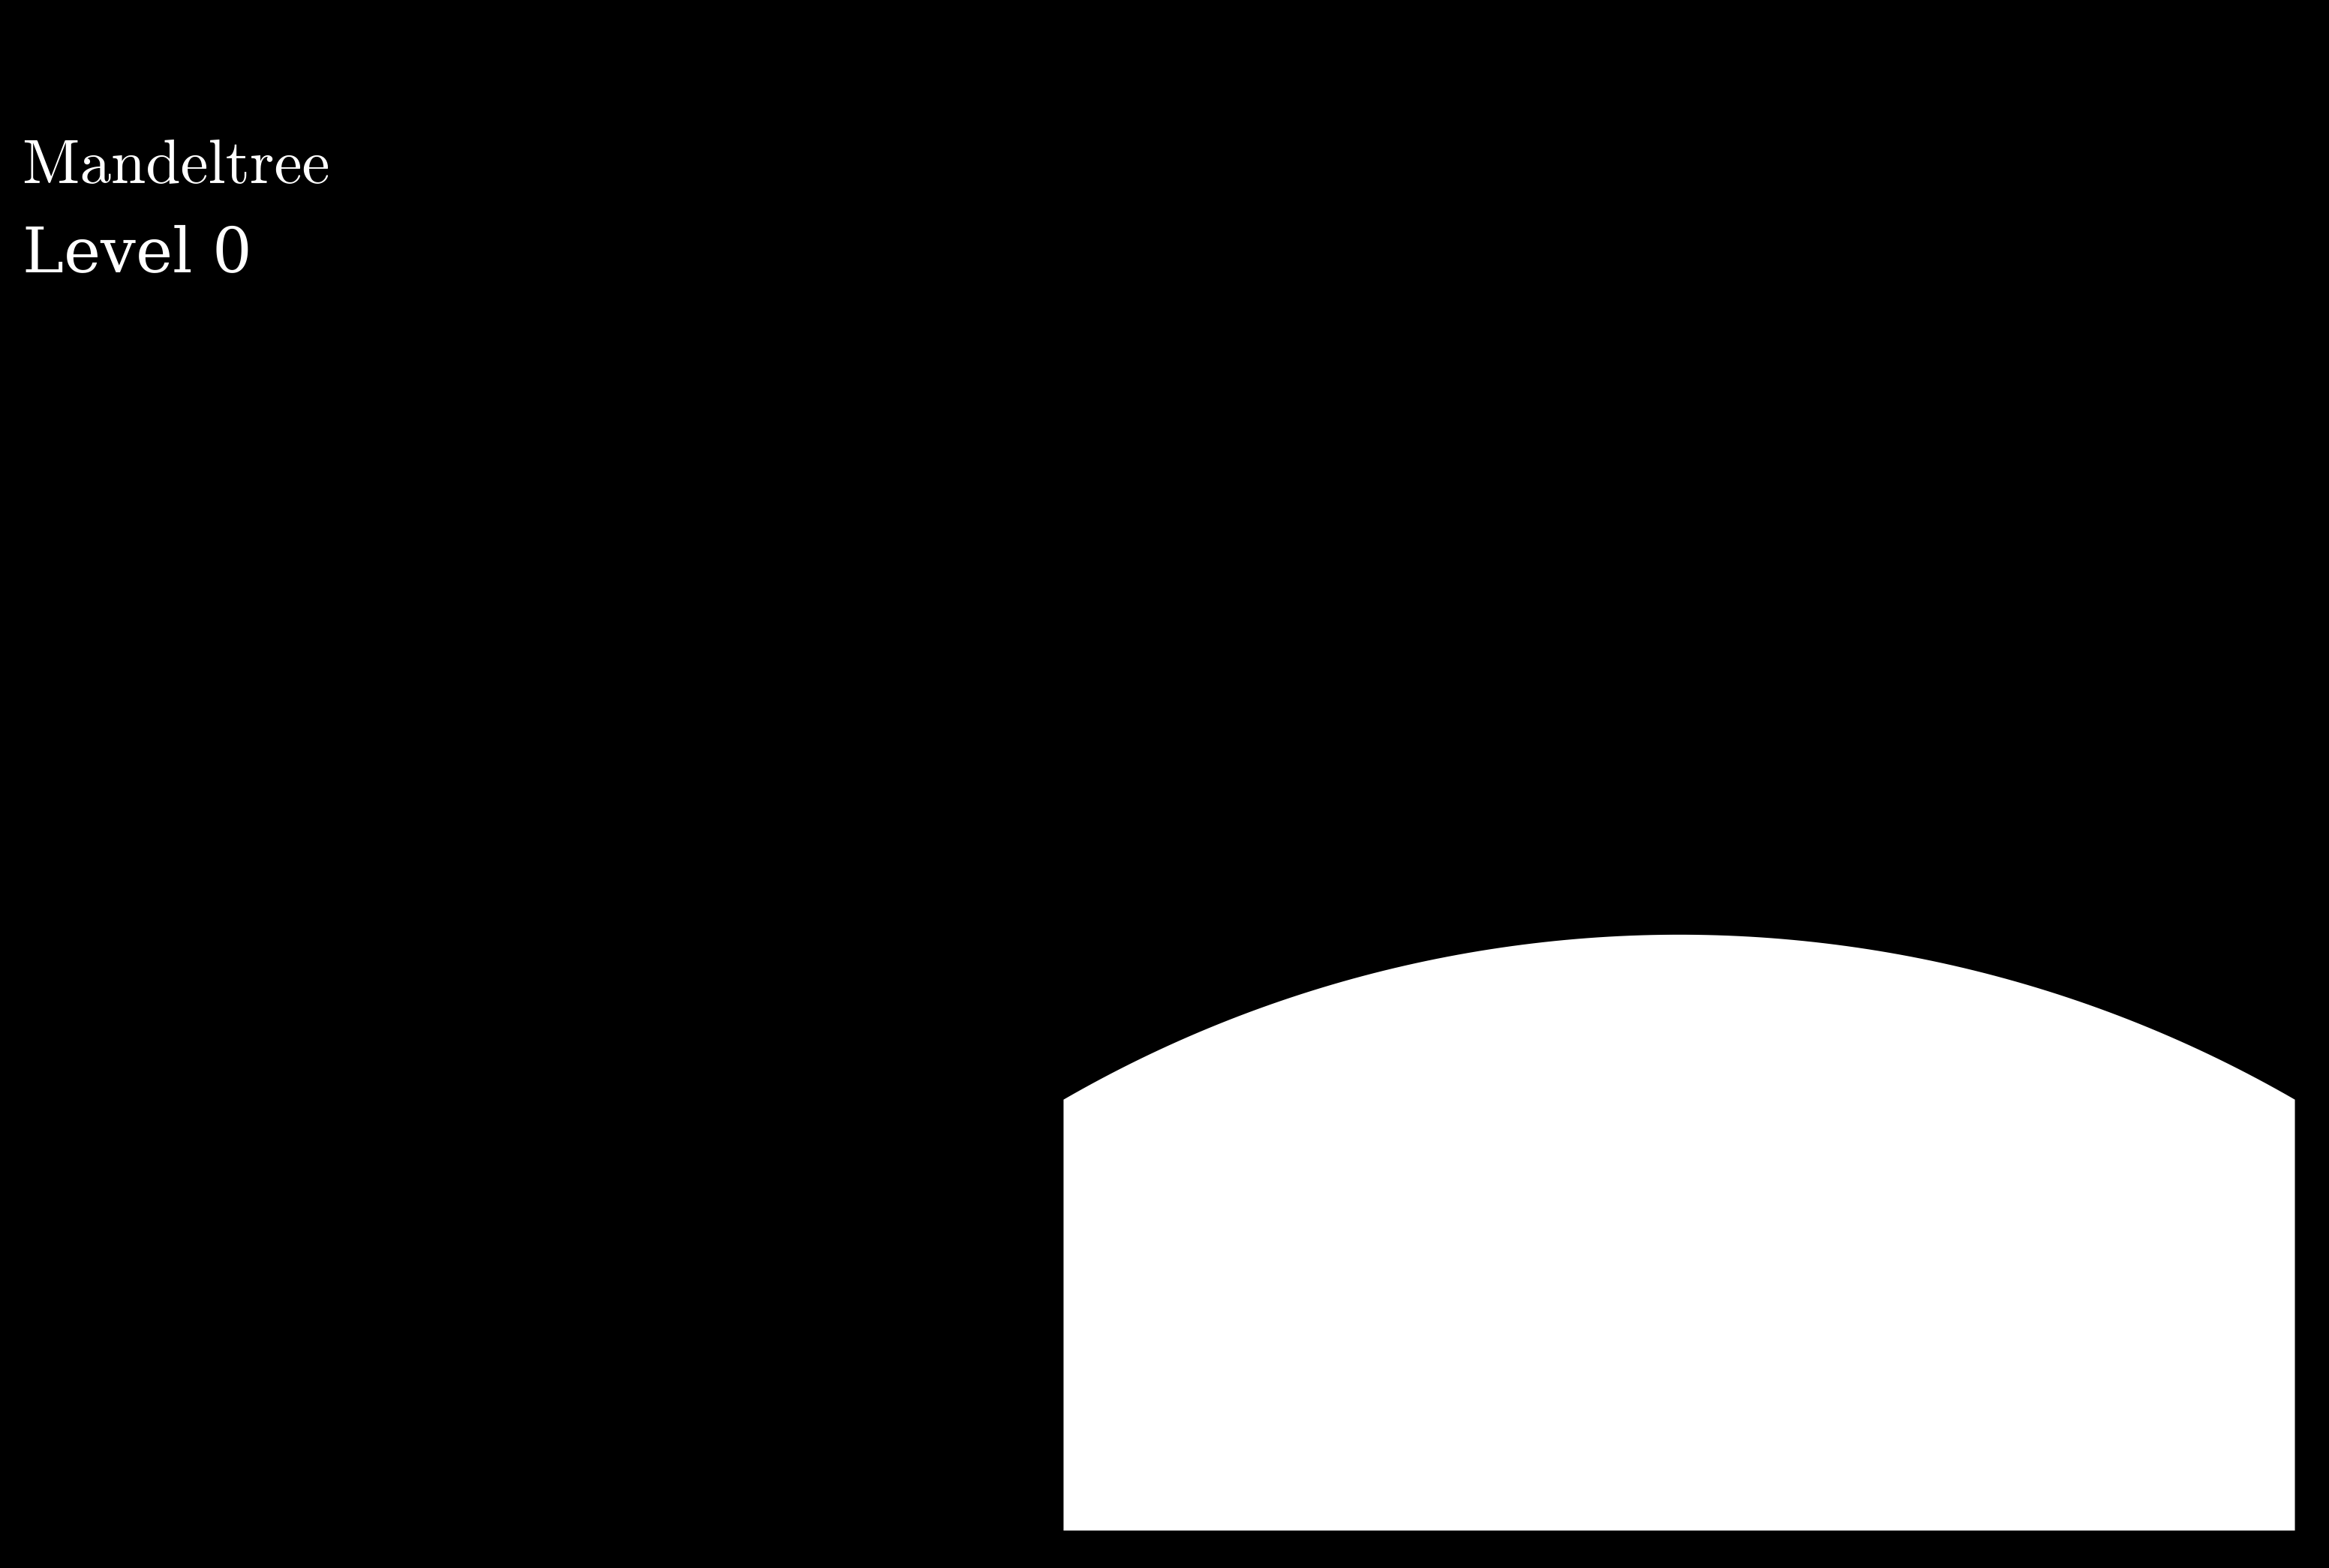

In [9]:
# 7. Figure / Visual Styling

# matplotlib setup
fig = plt.figure(figsize=(12.8, 7.2), dpi=300, facecolor="black")
ax = fig.add_axes([0.23, 0.03, 0.72, 0.94], facecolor=BACKGROUND_COLOR)

ax.set_aspect("equal")
ax.set_axis_off()
ax.set_xlim(xmin - xpad, xmax + xpad)
ax.set_ylim(ymin - ypad, ymax + ypad)

# Filled Peano region.
patch = Polygon(
    curve_to_polygon(
        static_curves[0]
    ),
    closed=True,
    facecolor=FILL_COLOR,
    edgecolor="none",
    antialiased=True
)

ax.add_patch(patch)

# Calculate the segment count for each recursive level.
arc_counts = [len(stage) for stage in stages]

# Optional stage label.
if SHOW_LABELS:
    title_text = fig.text(
        0.015,
        0.90,
        r"$\mathrm{Mandeltree}$",
        color="white",
        fontsize=20,
        ha="left",
        va="top"
    )

    label = fig.text(
        0.015,
        0.845,
        "Level 0",
        color="white",
        fontsize=20,
        ha="left",
        va="top"
    )

    arc_count_text = fig.text(
        0.015,
        0.79,
        "",
        color="white",
        fontsize=20,
        ha="left",
        va="top"
    )

    note_text = fig.text(
        0.015,
        0.735,
        "",
        color="white",
        fontsize=16,
        ha="left",
        va="top"
    )

else:
    label = None

In [10]:
# 8. Animation Update

def update(frame):
    # Initial hold on first figure
    if frame < initial_hold_frames:
        curve = static_curves[0]
        patch.set_xy(curve_to_polygon(curve))
        
        if label is not None:
            label.set_text("Level 0")
            arc_count_text.set_text(f"N = {arc_counts[0]:,}")
            
            return (patch, label, arc_count_text, note_text)
            
        return (patch,)

    # Which recursive transition are we currently in?
    local_frame = frame - initial_hold_frames

    # Special introduction: 1 -> 7, followed by a hold.
    if local_frame < block_frames:

        if local_frame < transition_frames:
            t = local_frame / (transition_frames - 1)
            curve = render_intro(0, t)
            description = "1 → 7 segments"

        else:
            curve = seven_curve
            description = "Canonical 7 segments"

        patch.set_xy(curve_to_polygon(curve))

        if label is not None:
            label.set_text(description)
            arc_count_text.set_text("N = 7")
            return (patch, label, arc_count_text, note_text)

        return (patch,)

    # Continue with the existing recursive transitions.
    local_frame -= block_frames
    
    transition_index = local_frame // block_frames
    position = local_frame % block_frames

    # Final frame safety
    if transition_index >= MAX_LEVEL:
        curve = static_curves[MAX_LEVEL]

        if label is not None:
            label.set_text(f"Level {MAX_LEVEL}")
            arc_count_text.set_text(f"N = {arc_counts[MAX_LEVEL]:,}")
            
    elif position < transition_frames:
        t = position / (transition_frames - 1)
        curve = (
            render_intro(1, t)
            if transition_index == 0
            else render_transition(transition_index, t)
        )

        if label is not None:
            label.set_text(f"Level {transition_index} → {transition_index + 1}")
            arc_count_text.set_text(f"N = {arc_counts[transition_index + 1]:,}")

    # Hold completed stage
    else:
        curve = static_curves[transition_index + 1]

        if label is not None:
            label.set_text(f"Level {transition_index + 1}")
            arc_count_text.set_text(f"N = {arc_counts[transition_index + 1]:,}")

    patch.set_xy(curve_to_polygon(curve))

    if label is not None:
        return (patch, label, arc_count_text, note_text)

    return (patch,)

In [12]:
# 9. Export

print("Exporting Mandeltree animation...")

output_file = "mandeltree.mp4"

animation = FuncAnimation(
    fig,
    update,
    frames=total_frames,
    interval=1000 / FPS,
    blit=False,
    repeat=False
)

# Display export progress.
def show_progress(current_frame, total):
    completed = current_frame + 1
    percentage = 100 * completed / total

    bar_width = 30
    filled = int(bar_width * completed / total)

    bar = "█" * filled + "░" * (bar_width - filled)

    print(
        f"\rRendering: |{bar}| {percentage:5.1f}% "
        f"({completed:,}/{total:,} frames)",
        end="",
        flush=True
    )

# Export MP4 using FFmpeg.
writer = FFMpegWriter(fps=FPS, bitrate=8000)

animation.save(
    output_file,
    writer=writer,
    progress_callback=show_progress
)

print(f"\nSaved: {output_file}")

plt.show()

Exporting Mandeltree animation...
Rendering: |██████████████████████████████| 100.0% (2,580/2,580 frames)
Saved: mandeltree.mp4
